# Paper Accessibility Analysis

This notebook analyzes the percentage of papers for which full text was successfully retrieved and investigates the reasons for inaccessibility.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plot style
sns.set_theme(style="whitegrid")

# Path to the index.csv file
# Adjust the run ID if necessary
run_id = "e2e_run_20251210_105347"
file_path = f"../searching_results/{run_id}/literature_searching/index.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(f"Successfully loaded data from {file_path}")
    print(f"Total records: {len(df)}")
    print(df.head())
else:
    print(f"File not found: {file_path}")
    # Create a dummy dataframe for demonstration if file is missing
    df = pd.DataFrame({
        'has_fulltext': [True, True, False, False, True],
        'pdf_path': ['path/to/pdf', 'path/to/pdf', None, 'path/to/pdf', 'path/to/pdf'],
        'html_path': [None, None, None, None, None]
    })

Successfully loaded data from ../searching_results/e2e_run_20251210_105347/literature_searching/index.csv
Total records: 118
                                           file_path         source  \
0  /home/chen/GNPS_SIM/agent/db_form_agent_system...  EuropePMC:MED   
1  /home/chen/GNPS_SIM/agent/db_form_agent_system...         PubMed   
2  /home/chen/GNPS_SIM/agent/db_form_agent_system...  EuropePMC:MED   
3  /home/chen/GNPS_SIM/agent/db_form_agent_system...  EuropePMC:MED   
4  /home/chen/GNPS_SIM/agent/db_form_agent_system...  EuropePMC:MED   

                                               title  \
0  Thorough Validation of Optimized Size Exclusio...   
1  Ferrate(VI) pretreatment before disinfection: ...   
2      Planet Contamination with Chemical Compounds.   
3  Non-targeted analysis with high-resolution mas...   
4  Permanganate Oxidation of Microcystin-LA: Kine...   

                                             authors  \
0  Laforce E, Dejaeger K, Vanoppen M, Cornelissen...   

In [2]:
# Calculate Full Text Statistics
total_papers = len(df)
full_text_available = df['has_fulltext'].sum()
full_text_missing = total_papers - full_text_available

percent_available = (full_text_available / total_papers) * 100
percent_missing = (full_text_missing / total_papers) * 100

print(f"Full Text Available: {full_text_available} ({percent_available:.2f}%)")
print(f"Full Text Missing: {full_text_missing} ({percent_missing:.2f}%)")

Full Text Available: 109 (92.37%)
Full Text Missing: 9 (7.63%)


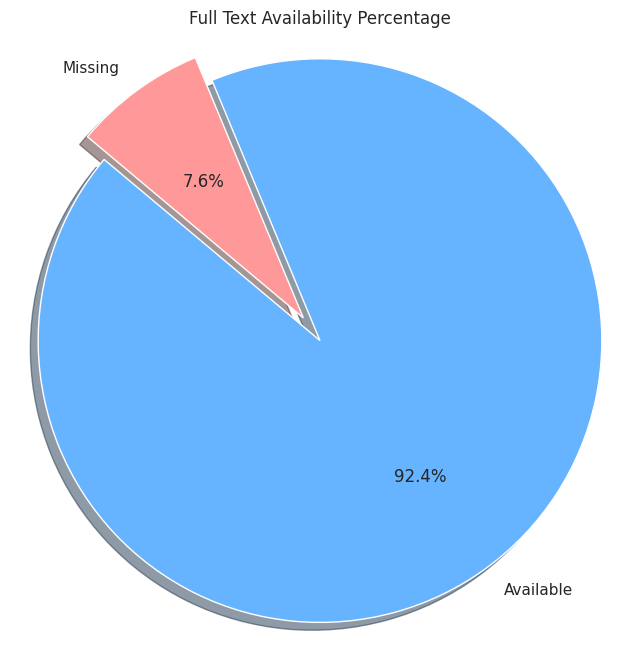

In [3]:
# Visualize Full Text Availability
plt.figure(figsize=(8, 8))
labels = ['Available', 'Missing']
sizes = [full_text_available, full_text_missing]
colors = ['#66b3ff', '#ff9999']
explode = (0.1, 0)  # explode the 1st slice

plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=140)
plt.title('Full Text Availability Percentage')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [4]:
# Analyze Accessibility Failure Reasons

def determine_status(row):
    if row['has_fulltext']:
        return 'Success'
    
    # Check if PDF path exists (meaning PDF was downloaded but maybe extraction failed)
    # Note: pd.isna() checks for NaN/None
    has_pdf = not pd.isna(row['pdf_path']) and str(row['pdf_path']).strip() != ''
    
    if has_pdf:
        return 'Extraction Failed'
    else:
        return 'PDF Not Found'

df['accessibility_status'] = df.apply(determine_status, axis=1)

# Filter for failures only
failure_df = df[df['accessibility_status'] != 'Success']
failure_counts = failure_df['accessibility_status'].value_counts()

print("Failure Reasons Breakdown:")
print(failure_counts)

Failure Reasons Breakdown:
accessibility_status
PDF Not Found    9
Name: count, dtype: int64


/tmp/ipykernel_5775/2969195614.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=failure_counts.values, y=failure_counts.index, palette='Reds_r')


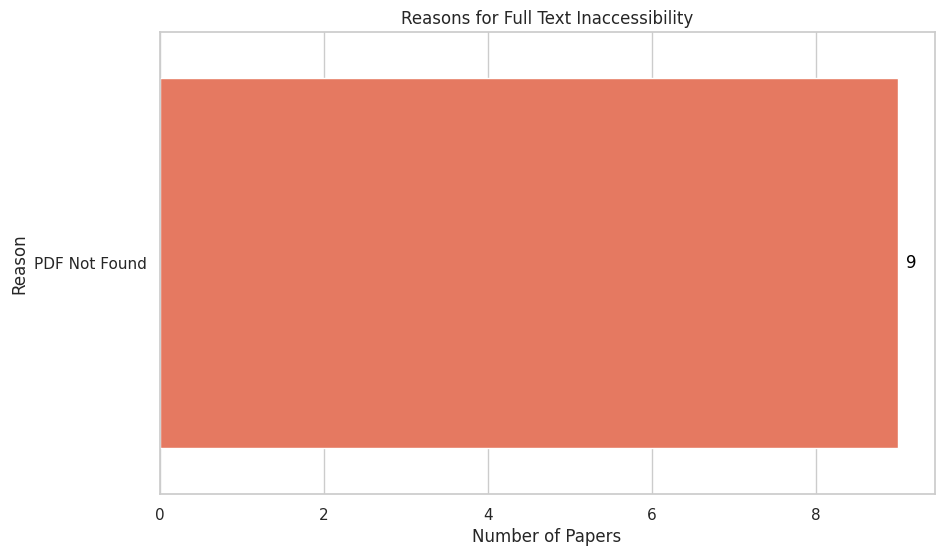

In [5]:
# Visualize Failure Reasons
if not failure_counts.empty:
    plt.figure(figsize=(10, 6))
    sns.barplot(x=failure_counts.values, y=failure_counts.index, palette='Reds_r')
    plt.title('Reasons for Full Text Inaccessibility')
    plt.xlabel('Number of Papers')
    plt.ylabel('Reason')
    
    # Add value labels to the bars
    for i, v in enumerate(failure_counts.values):
        plt.text(v + 0.1, i, str(v), color='black', va='center')
        
    plt.show()
else:
    print("No failures to visualize!")